In [4]:
import numpy as np
import joblib

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
X = np.load("processed/features.npy")
y = np.load("processed/labels.npy")

print("Features shape:", X.shape)
print("Labels shape:", y.shape)


Features shape: (21920, 205)
Labels shape: (21920,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 17536
Testing samples: 4384


In [7]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Feature scaling completed")


Feature scaling completed


In [8]:
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

print("XGBoost model initialized")


XGBoost model initialized


In [9]:
print("Training XGBoost model...")

xgb.fit(X_train_s, y_train)

print("Training complete")


Training XGBoost model...
Training complete


In [10]:
y_pred = xgb.predict(X_test_s)

acc = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {acc:.4f} ({acc*100:.2f}%)\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Non-Cough", "Cough"]))


Test Accuracy: 0.9542 (95.42%)

Classification Report:
              precision    recall  f1-score   support

   Non-Cough       0.96      0.97      0.97      3019
       Cough       0.94      0.91      0.93      1365

    accuracy                           0.95      4384
   macro avg       0.95      0.94      0.95      4384
weighted avg       0.95      0.95      0.95      4384



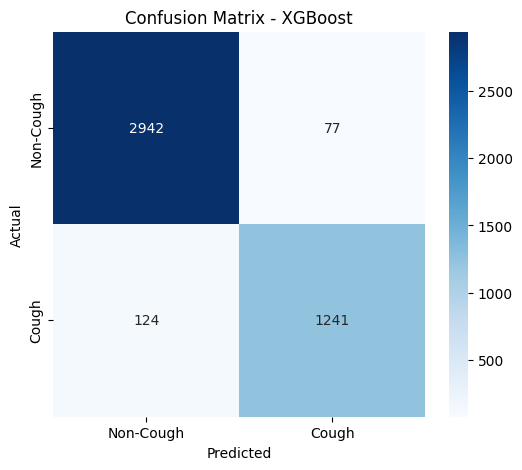

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Cough", "Cough"],
    yticklabels=["Non-Cough", "Cough"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBoost")
plt.show()


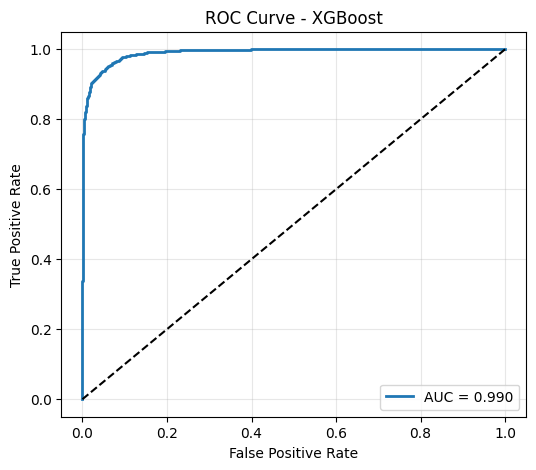

In [12]:
y_prob = xgb.predict_proba(X_test_s)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}", linewidth=2)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [13]:
joblib.dump(xgb, "models/xgboost.pkl")
joblib.dump(scaler, "models/scaler.pkl")

print("Model saved:")
print(" • models/xgboost.pkl")
print(" • models/scaler.pkl")


Model saved:
 • models/xgboost.pkl
 • models/scaler.pkl
